In [45]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(
    sys.version.split()[0],
    numpy.__version__,
    pandas.__version__,
    sklearn.__version__,
    matplotlib.__version__,
)

3.13.1 2.3.4 2.3.3 1.7.2 3.10.7


In [46]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3113

data = pd.read_csv("data/spambase.csv")
feature_names = [column for column in data.columns if column != "spam"]
X = data[feature_names].to_numpy()
y = data["spam"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


The dataset contains 4,204 emails. Each email has 57 features, and 39.9% of the emails are spam. I used 3,153 emails for training and 1,051 for testing.

In [47]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(
    DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED
)
rf = RandomForestClassifier(
    n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1
)

lr = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    LogisticRegression(max_iter=2000),
)
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)

knn = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15),
)
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)

members = [("lr", lr), ("knn", knn), ("tree", tree)]

## Part 1 · Bagging and out-of-bag estimates

In [49]:
def oob_mask(sample_indices, n_samples):
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=np.intp)] = False
    return mask

In [50]:
bag.fit(X_train, y_train)

n_train = len(y_train)
oob_shares = [
    oob_mask(sample_indices, n_train).mean()
    for sample_indices in bag.estimators_samples_
]

observed_oob = np.mean(oob_shares)
expected_oob = (1 - 1 / n_train) ** n_train

print(f"Observed OOB share:    {observed_oob:.3%}")
print(f"Expected OOB share:    {expected_oob:.3%}")
print(f"Observed in-bag share: {1 - observed_oob:.3%}")
print(f"Expected in-bag share: {1 - expected_oob:.3%}")

Observed OOB share:    36.795%
Expected OOB share:    36.782%
Observed in-bag share: 63.205%
Expected in-bag share: 63.218%


In [51]:
votes = np.zeros((n_train, 2), dtype=int)

for estimator, sample_indices in zip(bag.estimators_, bag.estimators_samples_):
    oob_rows = np.flatnonzero(oob_mask(sample_indices, n_train))
    predictions = estimator.predict(X_train[oob_rows]).astype(int)
    votes[oob_rows, predictions] += 1

oob_predictions = votes.argmax(axis=1)
manual_oob_accuracy = np.mean(oob_predictions == y_train)

print(f"Manual OOB accuracy:       {manual_oob_accuracy:.6f}")
print(f"Scikit-learn OOB accuracy: {bag.oob_score_:.6f}")
print("Scores match:", manual_oob_accuracy == bag.oob_score_)

Manual OOB accuracy:       0.937520
Scikit-learn OOB accuracy: 0.937520
Scores match: True


In [52]:
from IPython.display import display
from sklearn.model_selection import cross_validate

models = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}
cv_scores = {}

for name, model in models.items():
    cv_scores[name] = cross_validate(
        model, X_train, y_train, cv=cv, scoring="accuracy"
    )["test_score"]

paired_scores = {
    "bag − tree": cv_scores["bag"] - cv_scores["tree"],
    "rf − tree": cv_scores["rf"] - cv_scores["tree"],
    "bag_lr − lr": cv_scores["bag_lr"] - cv_scores["lr"],
}

def fold_table(results):
    table = pd.DataFrame.from_dict(
        results, orient="index", columns=[f"Fold {i}" for i in range(1, 6)]
    )
    return table.assign(
        Mean=table.mean(axis=1),
        SD=table.std(axis=1, ddof=0),
    ).round(6)

display(fold_table(cv_scores))
display(fold_table(paired_scores))

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,SD
tree,0.887480,0.904913,0.912837,0.896825,0.914286,0.903268,0.010064
bag,0.944532,0.931854,0.927100,0.930159,0.942857,0.935300,0.007041
rf,0.954041,0.942948,0.938193,0.944444,0.950794,0.946084,0.005662
lr,0.947702,0.942948,0.936609,0.936508,0.944444,0.941642,0.004427
bag_lr,0.947702,0.939778,0.935024,0.941270,0.944444,0.941644,0.004289


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,SD
bag − tree,0.057052,0.026941,0.014263,0.033333,0.028571,0.032032,0.014010
rf − tree,0.066561,0.038035,0.025357,0.047619,0.036508,0.042816,0.013816
bag_lr − lr,0.000000,-0.003170,-0.001585,0.004762,0.000000,0.000002,0.002655


### Did bagging help?

Bagging helped the decision tree. Its accuracy was higher on all five folds. The mean improvement was 3.20 percentage points, which was larger than the paired standard deviation of 1.40 percentage points. A single tree can change a lot when the training data changes. Combining votes from many trees makes the predictions more stable.

For logistic regression, the mean difference was only 0.0002 percentage points, while the paired standard deviation was 0.27 percentage points. The difference was within the usual variation across folds, so there was no clear winner. Logistic regression is usually more stable than a single decision tree, so bagging may have less effect.

In [53]:
rf.fit(X_train, y_train)

rf_oob = rf.oob_score_
rf_cv_mean = cv_scores["rf"].mean()
rf_cv_sd = cv_scores["rf"].std(ddof=0)

rf_test_accuracy = rf.score(X_test, y_test)
rf_test_se = np.sqrt(
    rf_test_accuracy * (1 - rf_test_accuracy) / len(y_test)
)

print(f"Forest OOB accuracy:  {rf_oob:.4%}")
print(f"Forest mean CV accuracy: {rf_cv_mean:.4%}")
print(f"Forest CV SD: {100 * rf_cv_sd:.4f} percentage points")
print(f"Forest test accuracy: {rf_test_accuracy:.4%}")
print(f"Test standard error: {100 * rf_test_se:.4f} percentage points")

print(f"OOB minus CV:  {100 * (rf_oob - rf_cv_mean):+.4f} percentage points")
print(f"OOB minus test: {100 * (rf_oob - rf_test_accuracy):+.4f} percentage points")
print(f"CV minus test:  {100 * (rf_cv_mean - rf_test_accuracy):+.4f} percentage points")

Forest OOB accuracy:  94.8620%
Forest mean CV accuracy: 94.6084%
Forest CV SD: 0.5662 percentage points
Forest test accuracy: 94.2912%
Test standard error: 0.7157 percentage points
OOB minus CV:  +0.2536 percentage points
OOB minus test: +0.5709 percentage points
CV minus test:  +0.3173 percentage points


### Random forest accuracy

The forest's OOB accuracy was 94.86%, and its mean CV accuracy was 94.61%. The gap was 0.25 percentage points, smaller than the CV standard deviation of 0.57 points. By the assignment's rule, the two scores agree, so the OOB score was a reasonable estimate of CV accuracy in this run.

The test accuracy was 94.29%. The OOB and CV scores were 0.57 and 0.32 percentage points higher, respectively. Both gaps were smaller than the test standard error of 0.72 percentage points.

## Part 2 · Evaluating the spam filter

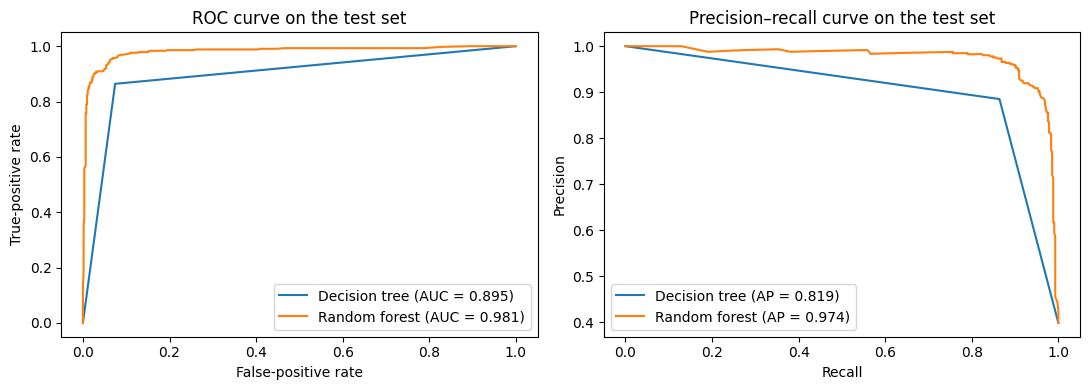

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

tree.fit(X_train, y_train)

tree_test_proba = tree.predict_proba(X_test)[:, 1]
rf_test_proba = rf.predict_proba(X_test)[:, 1]

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4))

for name, probabilities in [
    ("Decision tree", tree_test_proba),
    ("Random forest", rf_test_proba),
]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    ax_pr.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

ax_roc.set(
    title="ROC curve on the test set",
    xlabel="False-positive rate",
    ylabel="True-positive rate",
)
ax_pr.set(
    title="Precision–recall curve on the test set",
    xlabel="Recall",
    ylabel="Precision",
)

ax_roc.legend()
ax_pr.legend()
fig.tight_layout()
plt.show()

### What the curves show

The ROC curve shows how the share of detected spam changes as the filter flags more legitimate emails by mistake. 
The precision–recall curve shows how precision changes as the filter catches more spam. 

The random forest had a higher ROC AUC than the decision tree (0.981 vs. 0.895). This means it was better at separating spam from legitimate emails on the test set.

The random forest also had higher average precision (0.974 vs. 0.819). Its precision stayed higher over most of the recall range. This means that, at similar levels of recall, a larger share of the emails flagged by the forest were actually spam.

In [55]:
from sklearn.model_selection import cross_val_predict

rf_oof_proba = cross_val_predict(
    rf, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

oof_fpr, oof_recall, thresholds = roc_curve(
    y_train, rf_oof_proba, drop_intermediate=False
)

allowed = np.flatnonzero(oof_fpr <= 0.01)
best_recall = oof_recall[allowed].max()
tied = allowed[oof_recall[allowed] == best_recall]
best_index = tied[np.argmax(thresholds[tied])]
spam_threshold = thresholds[best_index]

print(f"Selected threshold: {spam_threshold}")
print(f"Training OOF FPR: {oof_fpr[best_index]:.4%}")
print(f"Training OOF recall: {oof_recall[best_index]:.4%}")

Selected threshold: 0.7533333333333333
Training OOF FPR: 0.9494%
Training OOF recall: 80.5887%


In [56]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

test_pred = (rf_test_proba >= spam_threshold).astype(int)

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
display(pd.DataFrame(
    cm,
    index=["Actual legitimate", "Actual spam"],
    columns=["Predicted legitimate", "Predicted spam"],
))

tn, fp, fn, tp = cm.ravel()
test_precision = precision_score(y_test, test_pred, zero_division=0)
test_recall = recall_score(y_test, test_pred)
test_fpr = fp / (tn + fp)

print(f"Test precision: {test_precision:.4%}")
print(f"Test recall:    {test_recall:.4%}")
print(f"Test FPR:       {test_fpr:.4%}")
print(f"Legitimate emails flagged as spam: {fp} out of {tn + fp}")
print(f"1% FPR target met: {'Yes' if test_fpr <= 0.01 else 'No'}")

,Predicted legitimate,Predicted spam
Actual legitimate,627,5
Actual spam,101,318


Test precision: 98.4520%
Test recall:    75.8950%
Test FPR:       0.7911%
Legitimate emails flagged as spam: 5 out of 632
1% FPR target met: Yes


### Did the filter meet the 1% target?

The random forest flagged 5 out of 632 legitimate test emails as spam. The false-positive rate was 0.79%, so the filter met the 1% target on the test set.

The filter caught 318 out of 419 spam emails, giving a recall of 75.90%. Of the emails it flagged as spam, 98.45% were actually spam.

In [58]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=3113,
    scoring="accuracy",
)

permutation_top5 = (
    pd.Series(perm.importances_mean, index=feature_names)
    .nlargest(5)
    .rename("Mean decrease in test accuracy")
)

impurity_top5 = (
    pd.Series(rf.feature_importances_, index=feature_names)
    .nlargest(5)
    .rename("Mean decrease in impurity")
)

print("Top 5 by permutation importance")
display(permutation_top5.to_frame())

print("Top 5 by impurity importance")
display(impurity_top5.to_frame())

Top 5 by permutation importance


,Mean decrease in test accuracy
word_freq_remove,0.031399
char_freq_exclam,0.019125
word_freq_hp,0.014748
char_freq_dollar,0.010752
word_freq_free,0.009039


Top 5 by impurity importance


,Mean decrease in impurity
char_freq_exclam,0.114085
char_freq_dollar,0.087027
word_freq_remove,0.084521
word_freq_free,0.072729
capital_run_length_average,0.064956


### Comparing feature importance

The feature `word_freq_remove` ranked first in permutation importance and third in impurity importance. When I shuffled this feature, the forest's test accuracy dropped by 3.14 percentage points on average. This was the largest drop among all features.

Impurity importance measures how much a feature's splits help the trees separate spam from legitimate emails during training. Permutation importance measures how much test accuracy drops when the feature's values are shuffled. The rankings can differ because these methods measure different things.

## Part 3 · Voting

In [59]:
def hard_vote(predictions, weights=None):
    """Return one class per sample using weighted majority voting."""
    labels = np.asarray(predictions)
    n_models, n_samples = labels.shape
    model_weights = [1] * n_models if weights is None else list(weights)
    winners = np.zeros(n_samples, dtype=labels.dtype)

    for sample in range(n_samples):
        totals = {0: 0}
        for model_index, weight in enumerate(model_weights):
            label = int(labels[model_index, sample])
            if isinstance(weight, np.generic):
                weight = weight.item()
            totals[label] = totals.get(label, 0) + weight

        winners[sample] = min(totals, key=lambda label: (-totals[label], label))

    return winners

In [60]:
np.testing.assert_array_equal(
    hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]), [0, 1, 0]
)
np.testing.assert_array_equal(
    hard_vote([[0, 1], [1, 0]]), [0, 0]
)
np.testing.assert_array_equal(
    hard_vote([[0, 1], [1, 0]], weights=[1, 2]), [1, 0]
)
np.testing.assert_array_equal(
    hard_vote([[2, 0], [2, 1], [0, 1]]), [2, 1]
)
np.testing.assert_array_equal(
    hard_vote([[2, 3], [3, 2]], weights=[0, 0]), [0, 0]
)

print("All hard_vote checks passed.")

All hard_vote checks passed.


In [61]:
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier

member_predictions = {
    name: clone(model).fit(X_train, y_train).predict(X_test)
    for name, model in members
}

prediction_matrix = np.vstack(list(member_predictions.values()))
manual_hard_predictions = hard_vote(prediction_matrix)

hard_voting = VotingClassifier(members, voting="hard")
hard_voting.fit(X_train, y_train)
sklearn_hard_predictions = hard_voting.predict(X_test)

agreement = np.mean(manual_hard_predictions == sklearn_hard_predictions)
print(f"Agreement with scikit-learn: {agreement:.2%}")

Agreement with scikit-learn: 100.00%


In [63]:
from itertools import combinations

disagreement_rows = []

for first, second in combinations(member_predictions, 2):
    disagreement = np.mean(
        member_predictions[first] != member_predictions[second]
    )
    disagreement_rows.append({
        "Model pair": f"{first} vs {second}",
        "Test disagreement": f"{disagreement:.2%}",
    })

display(pd.DataFrame(disagreement_rows).set_index("Model pair"))

,Test disagreement
Model pair,
lr vs knn,5.33%
lr vs tree,9.99%
knn vs tree,9.99%


In [64]:
soft_voting = VotingClassifier(members, voting="soft")

voting_cv_scores = {
    "lr": cv_scores["lr"],
    "tree": cv_scores["tree"],
}

for name, model in [
    ("knn", knn),
    ("hard voting", hard_voting),
    ("soft voting", soft_voting),
]:
    voting_cv_scores[name] = cross_validate(
        model, X_train, y_train, cv=cv, scoring="accuracy"
    )["test_score"]

member_names = ["lr", "knn", "tree"]
best_member = max(member_names, key=lambda name: voting_cv_scores[name].mean())

print(f"Best individual model by mean CV accuracy: {best_member}")
display(fold_table({
    name: voting_cv_scores[name]
    for name in member_names + ["hard voting", "soft voting"]
}))

voting_differences = {
    f"{name} − {best_member}": voting_cv_scores[name] - voting_cv_scores[best_member]
    for name in ["hard voting", "soft voting"]
}
display(fold_table(voting_differences))

Best individual model by mean CV accuracy: lr


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,SD
lr,0.947702,0.942948,0.936609,0.936508,0.944444,0.941642,0.004427
knn,0.930269,0.928685,0.916006,0.911111,0.926984,0.922611,0.007623
tree,0.887480,0.904913,0.912837,0.896825,0.914286,0.903268,0.010064
hard voting,0.955626,0.947702,0.942948,0.920635,0.942857,0.941954,0.011630
soft voting,0.947702,0.938193,0.938193,0.923810,0.942857,0.938151,0.007988


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,SD
hard voting − lr,0.007924,0.004754,0.006339,-0.015873,-0.001587,0.000311,0.008713
soft voting − lr,0.000000,-0.004754,0.001585,-0.012698,-0.001587,-0.003491,0.005059


### Did voting improve accuracy?

Logistic regression was the best individual model, with a mean CV accuracy of 94.16%.

Hard voting scored 0.03 percentage points higher than logistic regression on average. This difference was smaller than the paired standard deviation of 0.87 percentage points, so there was no clear winner.

Soft voting scored 0.35 percentage points lower than logistic regression on average. This difference was also smaller than the paired standard deviation of 0.51 percentage points, so there was no clear winner in this comparison either.

## Part 4 · Stacking

In [65]:
stack_oof_columns = []
stack_test_columns = []

for name, model in members:
    oof_proba = cross_val_predict(
        model, X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]
    stack_oof_columns.append(oof_proba)

    fitted_model = clone(model).fit(X_train, y_train)
    test_proba = fitted_model.predict_proba(X_test)[:, 1]
    stack_test_columns.append(test_proba)

stack_train_features = np.column_stack(stack_oof_columns)
stack_test_features = np.column_stack(stack_test_columns)

meta_model = LogisticRegression().fit(stack_train_features, y_train)
manual_stack_predictions = meta_model.predict(stack_test_features)

print("Stacking training data shape:", stack_train_features.shape)
print("Stacking test data shape:", stack_test_features.shape)

Stacking training data shape: (3153, 3)
Stacking test data shape: (1051, 3)


In [66]:
from sklearn.ensemble import StackingClassifier

stacking = StackingClassifier(
    estimators=members,
    final_estimator=LogisticRegression(),
    cv=cv,
)
stacking.fit(X_train, y_train)

sklearn_stack_predictions = stacking.predict(X_test)

max_coef_difference = np.max(
    np.abs(meta_model.coef_ - stacking.final_estimator_.coef_)
)

manual_stack_accuracy = np.mean(manual_stack_predictions == y_test)
sklearn_stack_accuracy = stacking.score(X_test, y_test)

print(f"Maximum coefficient difference: {max_coef_difference:.3g}")
print(
    "Test predictions match:",
    np.array_equal(manual_stack_predictions, sklearn_stack_predictions),
)
print(f"Manual stacking test accuracy:       {manual_stack_accuracy:.4%}")
print(f"Scikit-learn stacking test accuracy: {sklearn_stack_accuracy:.4%}")

Maximum coefficient difference: 0
Test predictions match: True
Manual stacking test accuracy:       93.1494%
Scikit-learn stacking test accuracy: 93.1494%


In [67]:
in_sample_columns = []

for name, model in members:
    fitted_model = clone(model).fit(X_train, y_train)
    train_proba = fitted_model.predict_proba(X_train)[:, 1]
    in_sample_columns.append(train_proba)

in_sample_features = np.column_stack(in_sample_columns)
in_sample_meta_model = LogisticRegression().fit(in_sample_features, y_train)

coefficient_table = pd.DataFrame(
    {
        "In-sample coefficient": in_sample_meta_model.coef_[0],
        "OOF coefficient": meta_model.coef_[0],
    },
    index=[name for name, model in members],
)

display(coefficient_table.round(4))

,In-sample coefficient,OOF coefficient
lr,2.0427,4.2203
knn,1.8706,2.6471
tree,8.2283,1.2694


### Why did the tree's coefficient change?

The decision tree's coefficient dropped from 8.2283 with in-sample predictions to 1.2694 with out-of-fold predictions. With in-sample predictions, the tree predicted emails it had already seen during training. This made its predictions look more reliable to the final model.

With out-of-fold predictions, each tree predicted emails it had not seen during training. These predictions gave a more realistic picture of how the tree performs on new emails, and the final model gave the tree less weight.

In [68]:
stacking_cv = cross_validate(
    stacking, X_train, y_train, cv=cv, scoring="accuracy"
)["test_score"]

stacking_cv_scores = {
    "stacking": stacking_cv,
    "soft voting": voting_cv_scores["soft voting"],
    best_member: voting_cv_scores[best_member],
}

display(fold_table(stacking_cv_scores))

stacking_differences = {
    f"stacking − {name}": stacking_cv - stacking_cv_scores[name]
    for name in ["soft voting", best_member]
}

display(fold_table(stacking_differences))

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,SD
stacking,0.952456,0.938193,0.941363,0.925397,0.939683,0.939418,0.008625
soft voting,0.947702,0.938193,0.938193,0.923810,0.942857,0.938151,0.007988
lr,0.947702,0.942948,0.936609,0.936508,0.944444,0.941642,0.004427


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,SD
stacking − soft voting,0.004754,0.000000,0.003170,0.001587,-0.003175,0.001267,0.002728
stacking − lr,0.004754,-0.004754,0.004754,-0.011111,-0.004762,-0.002224,0.006152


### Did stacking improve accuracy?

Stacking scored 0.13 percentage points higher than soft voting on average. This difference was smaller than the paired standard deviation of 0.27 percentage points, so there was no clear winner.

Stacking scored 0.22 percentage points lower than logistic regression, the best individual model. This gap was also smaller than the paired standard deviation of 0.62 percentage points, so there was no clear winner in this comparison either.

## Part 5 · AdaBoost and label noise

In [69]:
import math


def adaboost_step(y_true, y_pred, weights):
    """Return the learner's alpha and the updated sample weights."""
    wrong = np.asarray(y_true) != np.asarray(y_pred)
    new_weights = np.array(weights, dtype=float, copy=True)

    wrong_weight = float(new_weights[wrong].sum())
    correct_weight = float(new_weights[~wrong].sum())

    if wrong_weight == 0:
        return math.inf, new_weights / new_weights.sum()

    alpha = math.log(correct_weight) - math.log(wrong_weight)

    # After the AdaBoost update, each group holds half of the total weight.
    new_weights[wrong] = 0.5 * (new_weights[wrong] / wrong_weight)
    new_weights[~wrong] = 0.5 * (new_weights[~wrong] / correct_weight)

    return alpha, new_weights

In [70]:
examples = [
    ([1, 1, 0, 0], [1, 0, 0, 0], [1, 1, 1, 1],
     math.log(3), [1/6, 1/2, 1/6, 1/6]),

    ([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1],
     -math.log(3), [1/6, 1/6, 1/6, 1/2]),

    ([1, 0], [0, 0], [1, 1],
     0.0, [0.5, 0.5]),

    ([1, 0, 1], [1, 0, 1], [2, 2, 4],
     math.inf, [0.25, 0.25, 0.5]),

    ([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1],
     math.log(4), [0.125, 0.25, 0.5, 0.125]),
]

for labels, predictions, weights, expected_alpha, expected_weights in examples:
    alpha, updated_weights = adaboost_step(labels, predictions, weights)
    np.testing.assert_allclose(alpha, expected_alpha, atol=1e-12)
    np.testing.assert_allclose(updated_weights, expected_weights, atol=1e-12)

print("All five AdaBoost checks passed.")

All five AdaBoost checks passed.


In [71]:
x = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])

stump_1 = np.where(x <= 3.5, 1, 0)
stump_2 = np.where(x <= 9.5, 1, 0)
stump_3 = np.where(x <= 6.5, 0, 1)

toy_weights = np.full(10, 0.1)

for round_number, predictions in enumerate([stump_1, stump_2, stump_3], start=1):
    wrong = predictions != y_toy
    weighted_error = toy_weights[wrong].sum() / toy_weights.sum()
    alpha, toy_weights = adaboost_step(y_toy, predictions, toy_weights)

    print(f"Round {round_number}: weighted error = {weighted_error:.6f}, alpha = {alpha:.6f}")
    print("Updated weights:", np.round(toy_weights, 6))

Round 1: weighted error = 0.300000, alpha = 0.847298
Updated weights: [0.071429 0.071429 0.071429 0.071429 0.071429 0.071429 0.166667 0.166667
 0.166667 0.071429]
Round 2: weighted error = 0.214286, alpha = 1.299283
Updated weights: [0.045455 0.045455 0.045455 0.166667 0.166667 0.166667 0.106061 0.106061
 0.106061 0.045455]
Round 3: weighted error = 0.181818, alpha = 1.504077
Updated weights: [0.125    0.125    0.125    0.101852 0.101852 0.101852 0.064815 0.064815
 0.064815 0.125   ]


### Comparison with the lecture example

My results match the three-round example from the lecture. The weighted error decreased from 0.3000 in round 1 to 0.2143 in round 2 and 0.1818 in round 3. As the error decreased, alpha increased from 0.8473 to 1.2993 and then to 1.5041.

After round 1, each incorrectly classified example had a weight of about 0.1667, and each correctly classified example had a weight of about 0.0714. This gave the next model more reason to focus on the examples that the first model got wrong.

In [72]:
ada.fit(X_train, y_train)

sample_weights = np.full(len(y_train), 1 / len(y_train))
round_results = []

for round_index, stump in enumerate(ada.estimators_[:5]):
    predictions = stump.predict(X_train)
    wrong = predictions != y_train
    weighted_error = sample_weights[wrong].sum() / sample_weights.sum()

    alpha, sample_weights = adaboost_step(
        y_train, predictions, sample_weights
    )

    round_results.append({
        "Round": round_index + 1,
        "Manual error": weighted_error,
        "Scikit-learn error": ada.estimator_errors_[round_index],
        "Manual alpha": alpha,
        "Scikit-learn alpha": ada.estimator_weights_[round_index],
    })

round_table = pd.DataFrame(round_results).set_index("Round")
display(round_table.round(6))

error_gap = (round_table["Manual error"] - round_table["Scikit-learn error"]).abs()
alpha_gap = (round_table["Manual alpha"] - round_table["Scikit-learn alpha"]).abs()

print(f"Maximum absolute error difference: {error_gap.max():.3e}")
print(f"Maximum absolute alpha difference: {alpha_gap.max():.3e}")

,Manual error,Scikit-learn error,Manual alpha,Scikit-learn alpha
Round,,,,
1,0.209959,0.209959,1.325174,1.325174
2,0.239287,0.239287,1.156595,1.156595
3,0.273179,0.273179,0.978552,0.978552
4,0.271377,0.271377,0.987647,0.987647
5,0.337984,0.337984,0.672291,0.672291


Maximum absolute error difference: 1.110e-16
Maximum absolute alpha difference: 3.331e-16


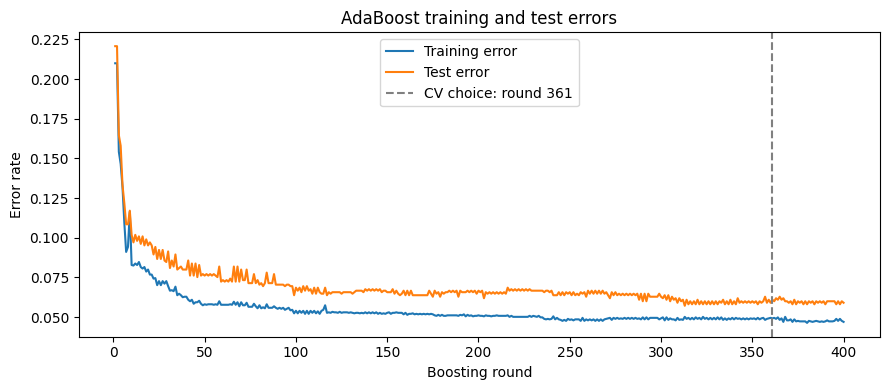

CV-selected round: 361
Test error at the CV-selected round: 6.0894%
Round with the lowest test error: 313
Lowest test error: 5.7088%
Test error gap: 0.3806 percentage points
Test standard error: 0.7376 percentage points
Gap exceeds one standard error: False


In [73]:
validation_counts = []
validation_sizes = []

for train_idx, val_idx in cv.split(X_train, y_train):
    fold_ada = clone(ada).fit(X_train[train_idx], y_train[train_idx])
    fold_scores = np.array(list(
        fold_ada.staged_score(X_train[val_idx], y_train[val_idx])
    ))
    validation_counts.append(np.rint(fold_scores * len(val_idx)).astype(int))
    validation_sizes.append(len(val_idx))

# Use a common denominator to handle exact ties across folds.
common_size = math.lcm(*validation_sizes)
cv_totals = sum(
    counts * (common_size // size)
    for counts, size in zip(validation_counts, validation_sizes)
)
chosen_idx = int(np.argmax(cv_totals))

train_errors = 1 - np.array(list(ada.staged_score(X_train, y_train)))
test_errors = 1 - np.array(list(ada.staged_score(X_test, y_test)))
best_test_idx = int(np.argmin(test_errors))
round_numbers = np.arange(1, len(test_errors) + 1)

plt.figure(figsize=(9, 4))
plt.plot(round_numbers, train_errors, label="Training error")
plt.plot(round_numbers, test_errors, label="Test error")
plt.axvline(chosen_idx + 1, linestyle="--", color="gray",
            label=f"CV choice: round {chosen_idx + 1}")
plt.xlabel("Boosting round")
plt.ylabel("Error rate")
plt.title("AdaBoost training and test errors")
plt.legend()
plt.tight_layout()
plt.show()

chosen_test_error = test_errors[chosen_idx]
p = 1 - chosen_test_error
test_se = np.sqrt(p * (1 - p) / len(y_test))
test_error_gap = chosen_test_error - test_errors[best_test_idx]

print(f"CV-selected round: {chosen_idx + 1}")
print(f"Test error at the CV-selected round: {chosen_test_error:.4%}")
print(f"Round with the lowest test error: {best_test_idx + 1}")
print(f"Lowest test error: {test_errors[best_test_idx]:.4%}")
print(f"Test error gap: {100 * test_error_gap:.4f} percentage points")
print(f"Test standard error: {100 * test_se:.4f} percentage points")
print(f"Gap exceeds one standard error: {test_error_gap > test_se}")

### AdaBoost error curves and the selected round

The horizontal axis shows the number of boosting rounds. The vertical axis shows the error rate, or the share of emails that AdaBoost classified incorrectly. The blue line shows training error, and the orange line shows test error.

Both errors dropped quickly in the early rounds. Later, the training error stayed close to 5%, while the test error stayed close to 6% and moved up and down slightly. This shows that most of the improvement happened early.

The dashed line marks round 361, which cross-validation selected using only the training folds. At that round, the test error was 6.09%. The lowest test error was 5.71% at round 313. The gap of 0.38 percentage points was smaller than one test standard error of 0.74 percentage points. I kept round 361 as the selected round.

In [74]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx


ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}

clean_accuracy = pd.Series({
    name: clone(model).fit(X_train, y_train).score(X_test, y_test)
    for name, model in noise_models.items()
})

noisy_accuracy = pd.DataFrame(
    index=pd.Index(range(1, 6), name="Draw"),
    columns=list(noise_models),
    dtype=float,
)
noisy_ada_runs = []

for r in range(5):
    y_noisy, flipped_indices = flip_labels(y_train, 0.20, SEED + r)

    for name, model in noise_models.items():
        fitted = clone(model).fit(X_train, y_noisy)
        noisy_accuracy.loc[r + 1, name] = fitted.score(X_test, y_test)

        if name == "ada200":
            noisy_ada_runs.append((fitted, y_noisy, flipped_indices))

accuracy_loss = clean_accuracy - noisy_accuracy

noise_summary = pd.DataFrame({
    "0% noise accuracy": clean_accuracy,
    "20% noise mean accuracy": noisy_accuracy.mean(),
    "20% noise accuracy SD": noisy_accuracy.std(ddof=0),
    "Mean accuracy loss": accuracy_loss.mean(),
    "Accuracy loss SD": accuracy_loss.std(ddof=0),
})

display(noise_summary.round(6))
display(accuracy_loss.T.add_prefix("Draw ").round(6))

,0% noise accuracy,20% noise mean accuracy,20% noise accuracy SD,Mean accuracy loss,Accuracy loss SD
tree,0.901047,0.732065,0.008629,0.168982,0.008629
rf,0.942912,0.891722,0.007281,0.051189,0.007281
ada200,0.933397,0.902569,0.005020,0.030828,0.005020


Draw,Draw 1,Draw 2,Draw 3,Draw 4,Draw 5
tree,0.181732,0.166508,0.176023,0.158896,0.161751
rf,0.039010,0.056137,0.046622,0.058040,0.056137
ada200,0.025690,0.030447,0.025690,0.033302,0.039010


In [75]:
weight_rows = []

for draw, (fitted_ada, y_noisy, flipped_indices) in enumerate(
    noisy_ada_runs, start=1
):
    weights = np.full(len(y_noisy), 1 / len(y_noisy))
    initial_share = weights[flipped_indices].sum()

    for stump in fitted_ada.estimators_:
        predictions = stump.predict(X_train)
        _, weights = adaboost_step(y_noisy, predictions, weights)

    weight_rows.append({
        "Draw": draw,
        "Initial weight share": initial_share,
        "Final weight share": weights[flipped_indices].sum(),
    })

weight_table = pd.DataFrame(weight_rows).set_index("Draw")
weight_summary = pd.DataFrame({
    "Mean": weight_table.mean(),
    "SD": weight_table.std(ddof=0),
})

display(weight_table.round(6))
display(weight_summary.round(6))

paired_loss_table = pd.DataFrame({
    f"{first} − {second}": accuracy_loss[first] - accuracy_loss[second]
    for first, second in combinations(accuracy_loss.columns, 2)
}).T

paired_loss_table.columns = [
    f"Draw {draw}" for draw in accuracy_loss.index
]

display(paired_loss_table.assign(
    Mean=paired_loss_table.mean(axis=1),
    SD=paired_loss_table.std(axis=1, ddof=0),
).round(6))

,Initial weight share,Final weight share
Draw,,
1,0.200127,0.405370
2,0.200127,0.402359
3,0.200127,0.406009
4,0.200127,0.395183
5,0.200127,0.396334


,Mean,SD
Initial weight share,0.200127,0.000000
Final weight share,0.401051,0.004508


,Draw 1,Draw 2,Draw 3,Draw 4,Draw 5,Mean,SD
tree − rf,0.142721,0.110371,0.129401,0.100856,0.105614,0.117793,0.015789
tree − ada200,0.156042,0.136061,0.150333,0.125595,0.122740,0.138154,0.013176
rf − ada200,0.013321,0.025690,0.020932,0.024738,0.017127,0.020362,0.004646


### How label noise affected the models

The decision tree lost the most accuracy. It lost 11.78 percentage points more than the random forest and 13.82 points more than AdaBoost on average. Both gaps were larger than their paired standard deviations of 1.58 and 1.32 points. The random forest also lost 2.04 points more than AdaBoost, a gap larger than its paired standard deviation of 0.46 points.

A single decision tree can split the data in ways that fit incorrect labels. A random forest combines many trees, which can reduce the effect of those splits. This helps explain why the single tree lost more accuracy than the forest.

The emails with flipped labels held 20.01% of the total weight before boosting and 40.11% on average after the final round. AdaBoost gives more weight to examples it gets wrong, so it paid more attention to these emails. Even with this extra weight on flipped labels, AdaBoost lost the least test accuracy in this experiment.